# JWST accessible V3PA vs. ecliptic latitude

Reference plot for observation planning: **what range(s) of JWST V3 position angle (V3PA) are accessible, over the course of a year, as a function of a target's ecliptic latitude?**

Targets near the ecliptic have two short visibility windows per year with narrow PA ranges; targets near the ecliptic poles (the continuous viewing zone) are visible all year and the PA range sweeps through the full 360 deg.

**Approach**

1. Build a grid of targets spanning ecliptic latitude 0-90 deg (fixed, arbitrary longitude) and convert to ICRS RA/Dec.
2. Run the STScI `jwst_gtvt` command-line tool over a one-year baseline, caching the ephemeris CSVs.
3. For each day when the target is **in the field of regard** (`in_FOR`), take the observatory `V3PA_min_pa_angle` / `V3PA_max_pa_angle` range. (`jwst_gtvt` fills these columns even when the target is not observable, so the `in_FOR` mask is essential.) A range with min > max wraps through 0/360.
4. Accumulate the accessible V3PAs per day into a 2-D (latitude x V3PA) grid, shaded by fraction of the year accessible.

> Step 2 needs network access to JPL Horizons unless the CSVs are already cached in `gtvt_output/`.

## 0. Setup

In [1]:
import subprocess
import shutil
import os
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from astropy.coordinates import SkyCoord
import astropy.units as u

GTVT_EXE = shutil.which("jwst_gtvt")
if GTVT_EXE is None:
    raise RuntimeError("Could not find the 'jwst_gtvt' command on PATH.")
print("Using jwst_gtvt at:", GTVT_EXE)

Using jwst_gtvt at: /Users/mperrin/miniconda3/envs/stenv-py3.14-2026.05.08/bin/jwst_gtvt


## 1. Configuration

In [2]:
# Ecliptic latitudes and longitudes to sample, in degrees. V3PA is measured from
# celestial north, so the accessible range is rotated by the PA of ecliptic north
# at the target, which depends on ecliptic longitude. Hence one panel per longitude.
ECL_LATS = np.arange(-90, 90.1, 2.5)
ECL_LONS = [0, 90, 180, 270]
N_WORKERS = 4  # parallel jwst_gtvt processes
N_RETRIES = 4  # attempts per jwst_gtvt call

# Any full year works; the pattern repeats annually.
START_DATE = "2024-01-01"
END_DATE = "2025-01-01"

# Cache of per-target jwst_gtvt ephemeris CSVs.
OUTPUT_DIR = Path("gtvt_output")
OUTPUT_DIR.mkdir(exist_ok=True)

N_PA_BINS = 360  # 1 deg bins

## 2. Target list: ecliptic latitude grid -> ICRS RA/Dec

In [3]:
def target_name(lon, lat):
    # At the poles the longitude is meaningless, so share one ephemeris.
    if abs(lat) == 90:
        lon = 0
    return f"lon{int(lon):03d}_lat{lat:+06.1f}"


targets = []
for lon in ECL_LONS:
    for lat in ECL_LATS:
        c_icrs = SkyCoord(
            lon=float(lon) * u.deg, lat=float(lat) * u.deg,
            frame="barycentrictrueecliptic",
        ).icrs
        targets.append(
            {
                "ecl_lon": float(lon),
                "ecl_lat": float(lat),
                "ra_deg": c_icrs.ra.deg,
                "dec_deg": c_icrs.dec.deg,
                "name": target_name(lon, lat),
            }
        )

targets_df = pd.DataFrame(targets)
# Unique ephemerides to compute (pole targets are shared across longitudes)
unique_targets_df = targets_df.drop_duplicates("name")
print(len(targets_df), "targets,", len(unique_targets_df), "unique ephemerides")
targets_df.head()

292 targets, 286 unique ephemerides


,ecl_lon,ecl_lat,ra_deg,dec_deg,name
0,0.0,-90.0,89.999985,-66.560719,lon000_lat-090.0
1,0.0,-87.5,83.736182,-66.435086,lon000_lat-087.5
2,0.0,-85.0,77.595792,-66.062484,lon000_lat-085.0
3,0.0,-82.5,71.687311,-65.454191,lon000_lat-082.5
4,0.0,-80.0,66.093771,-64.627202,lon000_lat-080.0


## 3. Run `jwst_gtvt` for each target (cached)

> **Runtime heads-up:** each `jwst_gtvt` call takes roughly 10-15 s (it queries JPL Horizons), and this grid needs ~286 unique ephemerides. Run from scratch with 4 parallel workers, this step takes on the order of 15-20 minutes (several times longer if run serially, and it needs network access). Results are cached as CSVs in `gtvt_output/`, so re-running the notebook afterwards is fast.

In [4]:
def run_gtvt(ra_deg, dec_deg, out_csv, start_date=START_DATE, end_date=END_DATE,
             target_name=None, force=False):
    """Run the jwst_gtvt CLI for one target, writing its ephemeris to CSV."""
    out_csv = Path(out_csv)
    if out_csv.exists() and not force:
        return out_csv

    cmd = [
        GTVT_EXE,
        f"--ra={ra_deg}",
        f"--dec={dec_deg}",
        f"--start_date={start_date}",
        f"--end_date={end_date}",
        f"--write_ephemeris={out_csv}",
        "--silent",
    ]
    if target_name:
        cmd.append(f"--target_name={target_name}")

    # jwst_gtvt calls plt.show() unless a plot file is requested; the Agg
    # backend makes that a no-op so no window pops up.
    env = {**os.environ, "MPLBACKEND": "Agg"}
    # Horizons queries occasionally fail transiently (esp. when run in
    # parallel), so retry a few times before giving up.
    for attempt in range(N_RETRIES):
        result = subprocess.run(cmd, capture_output=True, text=True, env=env)
        if result.returncode == 0 and out_csv.exists():
            return out_csv
        out_csv.unlink(missing_ok=True)
        time.sleep(5 * (attempt + 1))
    raise RuntimeError(
        f"jwst_gtvt failed for RA={ra_deg}, Dec={dec_deg}\n"
        f"stdout:\n{result.stdout}\nstderr:\n{result.stderr}"
    )


from concurrent.futures import ThreadPoolExecutor


def _run_row(row):
    return run_gtvt(
        row.ra_deg, row.dec_deg, OUTPUT_DIR / f"{row.name}.csv",
        target_name=row.name,
    )


# Already-cached targets return immediately; the rest are network-bound.
with ThreadPoolExecutor(max_workers=N_WORKERS) as pool:
    results = list(pool.map(_run_row, unique_targets_df.itertuples()))

csv_paths = {
    (row.ecl_lon, row.ecl_lat): OUTPUT_DIR / f"{row.name}.csv"
    for row in targets_df.itertuples()
}
print(f"{len(results)} ephemeris files ready in {OUTPUT_DIR}/")

286 ephemeris files ready in gtvt_output/


## 4. Read ephemerides; keep V3PA ranges only on days the target is in the field of regard

In [5]:
per_target_data = {}
for key, csv_path in csv_paths.items():
    df = pd.read_csv(csv_path)
    sub = df[["V3PA_min_pa_angle", "V3PA_max_pa_angle", "in_FOR"]].rename(
        columns={"V3PA_min_pa_angle": "pa_min", "V3PA_max_pa_angle": "pa_max"}
    )
    # jwst_gtvt fills the PA columns even outside the field of regard
    # (garbage values, e.g. ranges 180 deg wide), so mask those days.
    sub.loc[~sub["in_FOR"].astype(bool), ["pa_min", "pa_max"]] = np.nan
    per_target_data[key] = sub

# Days in the field of regard, at a few latitudes (rows) per longitude (columns)
pd.DataFrame(
    {
        lon: {lat: int(per_target_data[(float(lon), float(lat))]["pa_min"].notna().sum())
              for lat in (-90, -45, 0, 45, 90)}
        for lon in ECL_LONS
    }
)

,0,90,180,270
-90,366,366,366,366
-45,199,186,198,192
0,103,100,102,103
45,191,194,190,201
90,366,366,366,366


## 5. Build the (ecliptic latitude x V3PA) density grid

In [6]:
pa_edges = np.linspace(0, 360, N_PA_BINS + 1)
pa_centers = 0.5 * (pa_edges[:-1] + pa_edges[1:])

density_grids = {lon: np.zeros((len(ECL_LATS), N_PA_BINS)) for lon in ECL_LONS}

for lon in ECL_LONS:
    for i, ecl_lat in enumerate(ECL_LATS):
        df = per_target_data[(float(lon), float(ecl_lat))]
        n_days_total = len(df)

        for pa_min, pa_max in zip(df["pa_min"].values, df["pa_max"].values):
            if np.isnan(pa_min) or np.isnan(pa_max):
                continue  # target not in the field of regard that day
            if pa_min <= pa_max:
                mask = (pa_centers >= pa_min) & (pa_centers <= pa_max)
            else:
                # Range wraps through the 0/360 boundary
                mask = (pa_centers >= pa_min) | (pa_centers <= pa_max)
            density_grids[lon][i, mask] += 1

        density_grids[lon][i, :] /= n_days_total  # -> fraction of the year accessible

vmax = max(g.max() for g in density_grids.values())
print("max fraction-of-year accessible in any grid:", vmax)

max fraction-of-year accessible in any grid: 0.14713896457765668


## 6. Plot: fraction of year each V3PA is accessible

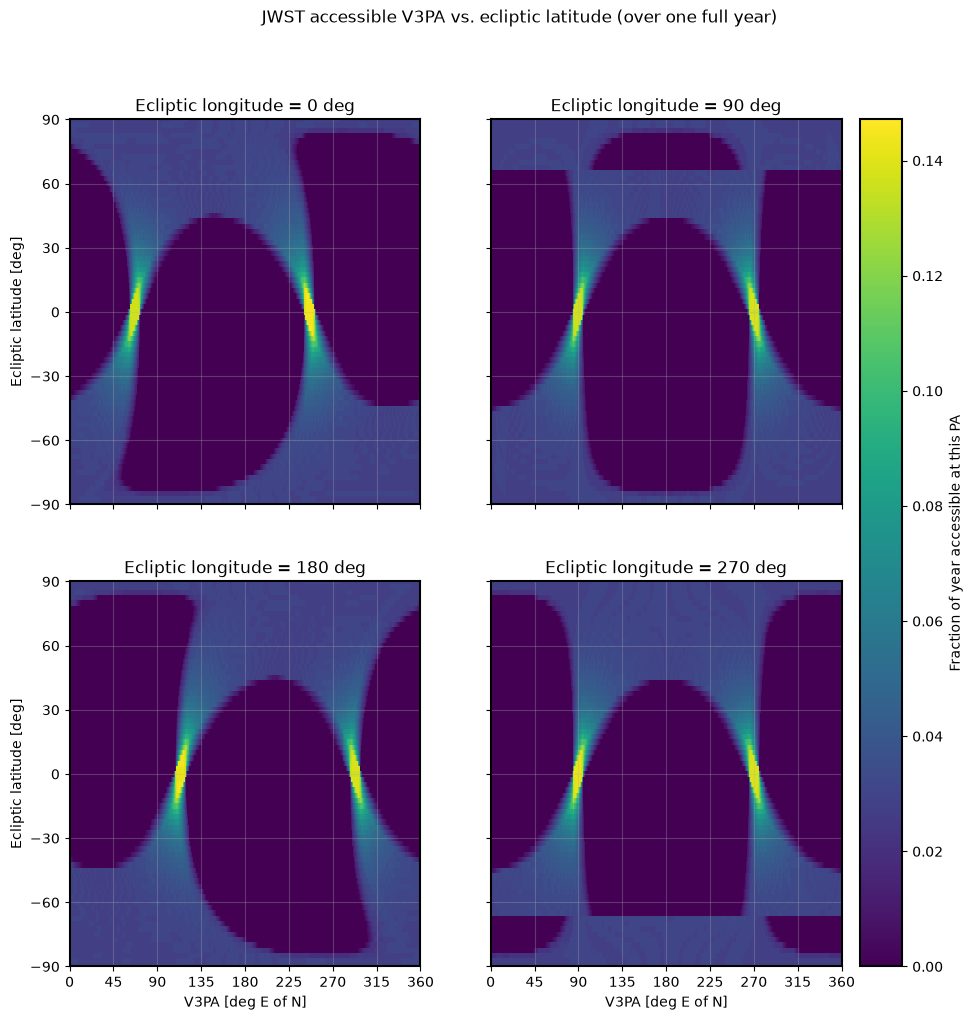

In [7]:
fig, axs = plt.subplots(2, 2, figsize=(12, 11), sharex=True, sharey=True)

for ax, lon in zip(axs.flat, ECL_LONS):
    pcm = ax.pcolormesh(
        pa_centers, ECL_LATS, density_grids[lon],
        shading="nearest", cmap="viridis", vmin=0, vmax=vmax,
    )
    ax.set_xlim(0, 360)
    ax.set_ylim(-90, 90)
    ax.set_xticks(np.arange(0, 361, 45))
    ax.set_yticks(np.arange(-90, 91, 30))
    ax.set_title(f"Ecliptic longitude = {lon} deg")
    ax.grid(alpha=0.3)

for ax in axs[1]:
    ax.set_xlabel("V3PA [deg E of N]")
for ax in axs[:, 0]:
    ax.set_ylabel("Ecliptic latitude [deg]")

fig.suptitle("JWST accessible V3PA vs. ecliptic latitude (over one full year)")
fig.colorbar(pcm, ax=axs, pad=0.02, label="Fraction of year accessible at this PA")
fig.savefig("jwst_v3pa_vs_ecliptic_latitude.png", dpi=200)
plt.show()

## 7. PA from ecliptic north

Equivalent to the plot above but with position angle measured from *ecliptic* north instead of celestial north (i.e. V3PA minus θ_ecl, where θ_ecl is the PA of ecliptic north). In this frame the accessible range depends only on ecliptic latitude (not longitude), so a single panel suffices (the four longitudes are averaged as a consistency check). To get the ordinary V3PA (E of celestial N), add the offset θ_ecl(lon, lat) from the lookup map in section 8: `V3PA = PA_eclN + θ_ecl`.

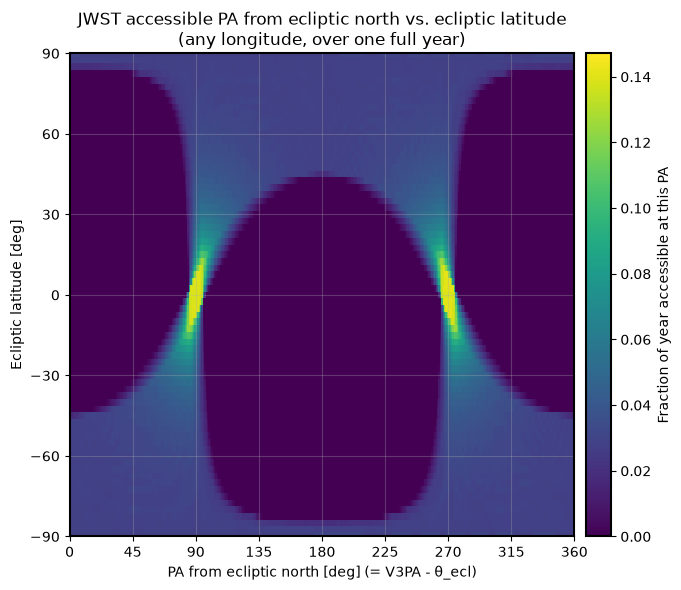

In [8]:
ECL_NORTH_POLE = SkyCoord(
    lon=0 * u.deg, lat=90 * u.deg, frame="barycentrictrueecliptic"
).icrs


def theta_ecl_deg(lon, lat):
    """PA of ecliptic north (deg E of celestial N) at ecliptic (lon, lat)."""
    lat = np.clip(lat, -89.999, 89.999)  # PA is undefined exactly at the pole
    c = SkyCoord(lon=lon * u.deg, lat=lat * u.deg, frame="barycentrictrueecliptic")
    return c.icrs.position_angle(ECL_NORTH_POLE).deg


rel_grid = np.zeros((len(ECL_LATS), N_PA_BINS))
for i, ecl_lat in enumerate(ECL_LATS):
    # The pole ephemeris is shared across longitudes, so use it only once.
    lons = [0] if abs(ecl_lat) == 90 else ECL_LONS
    for lon in lons:
        df = per_target_data[(float(lon), float(ecl_lat))]
        theta_ecl = theta_ecl_deg(lon, ecl_lat)
        for pa_min, pa_max in zip(df["pa_min"].values, df["pa_max"].values):
            if np.isnan(pa_min) or np.isnan(pa_max):
                continue
            a, b = (pa_min - theta_ecl) % 360, (pa_max - theta_ecl) % 360
            if a <= b:
                mask = (pa_centers >= a) & (pa_centers <= b)
            else:
                mask = (pa_centers >= a) | (pa_centers <= b)
            rel_grid[i, mask] += 1 / (len(df) * len(lons))

fig, ax = plt.subplots(figsize=(7, 6))
pcm = ax.pcolormesh(
    pa_centers, ECL_LATS, rel_grid,
    shading="nearest", cmap="viridis", vmin=0, vmax=vmax,
)
ax.set_xlim(0, 360)
ax.set_ylim(-90, 90)
ax.set_xticks(np.arange(0, 361, 45))
ax.set_yticks(np.arange(-90, 91, 30))
ax.grid(alpha=0.3)
ax.set_xlabel("PA from ecliptic north [deg] (= V3PA - θ_ecl)")
ax.set_ylabel("Ecliptic latitude [deg]")
ax.set_title("JWST accessible PA from ecliptic north vs. ecliptic latitude\n(any longitude, over one full year)")
fig.colorbar(pcm, ax=ax, pad=0.02, label="Fraction of year accessible at this PA")
fig.tight_layout()
fig.savefig("jwst_pa_from_ecliptic_north_vs_ecliptic_latitude.png", dpi=200)
plt.show()

## 8. Lookup: θ_ecl, the PA of ecliptic north (deg E of celestial N)

`V3PA = PA_eclN + θ_ecl(lon, lat)`. Contours are labelled in degrees; the colormap is cyclic. Contours are interrupted where θ_ecl jumps by 180 deg, which happens at the celestial pole (ecliptic latitude about +/-66.6 deg at lon 90/270), where PA is discontinuous.

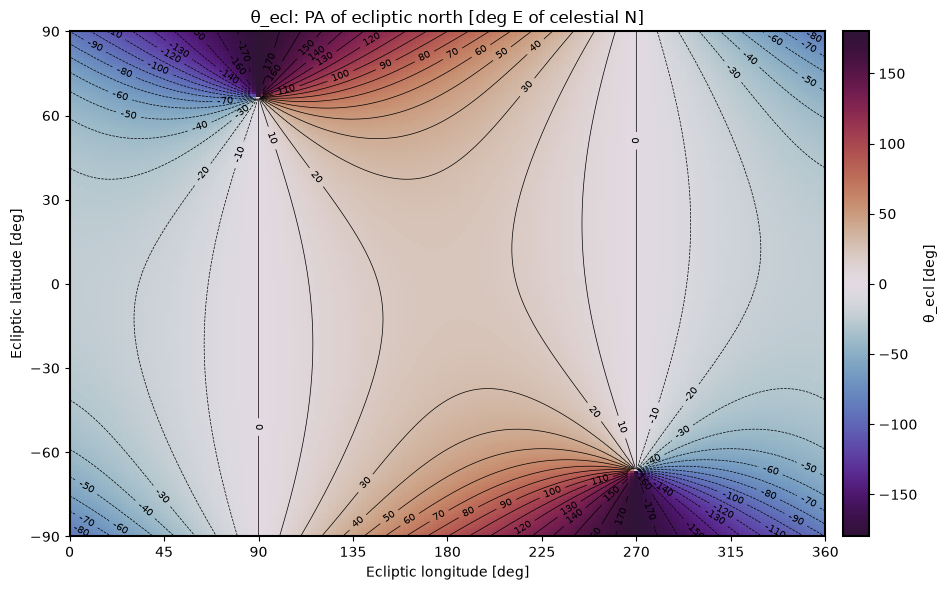

In [9]:
map_lons = np.arange(0, 360.1, 2.0)
map_lats = np.arange(-90, 90.1, 1.0)
LON, LAT = np.meshgrid(map_lons, map_lats)
theta_map = (theta_ecl_deg(LON, LAT) + 180) % 360 - 180  # -180..180

# Mask cells next to a +/-180 wrap so contour lines aren't drawn across it
jump = np.zeros_like(theta_map, dtype=bool)
for axis in (0, 1):
    big = np.abs(np.diff(theta_map, axis=axis)) > 180
    lo = [slice(None)] * 2
    hi = [slice(None)] * 2
    lo[axis], hi[axis] = slice(0, -1), slice(1, None)
    jump[tuple(lo)] |= big
    jump[tuple(hi)] |= big
theta_masked = np.ma.masked_where(jump, theta_map)

fig, ax = plt.subplots(figsize=(10, 6))
pcm = ax.pcolormesh(
    map_lons, map_lats, theta_map, shading="nearest", cmap="twilight_shifted",
    vmin=-180, vmax=180,
)
cs = ax.contour(
    map_lons, map_lats, theta_masked, levels=np.arange(-170, 171, 10),
    colors="k", linewidths=0.5,
)
ax.clabel(cs, fmt="%d", fontsize=7)
ax.set_xlim(0, 360)
ax.set_ylim(-90, 90)
ax.set_xticks(np.arange(0, 361, 45))
ax.set_yticks(np.arange(-90, 91, 30))
ax.set_xlabel("Ecliptic longitude [deg]")
ax.set_ylabel("Ecliptic latitude [deg]")
ax.set_title("θ_ecl: PA of ecliptic north [deg E of celestial N]")
fig.colorbar(pcm, ax=ax, pad=0.02, label="θ_ecl [deg]")
fig.tight_layout()
fig.savefig("jwst_ecliptic_north_pa_theta_ecl.png", dpi=200)
plt.show()